# Applying assumptions to a flight schedule

You’ve explored lounge eligibility and made thoughtful assumptions—now it’s time to bring it all together. In this part of the task, you’ll apply your model to a real-world scenario using a sample flight schedule.

Instructions: 

1. Download and review the flight schedule provided below.

2. Assign each flight to one of your defined categories (e.g., by time of day, route type, or destination region).

3. Apply your estimated eligibility percentages to each category to calculate the number of passengers likely to use each lounge.

Note: The dataset contains a large number of flights. You do not need to analyze all of them. Instead, select a representative sample (e.g., flights within a specific time window or set of destinations) that allows you to test your groupings and apply your assumptions meaningfully.



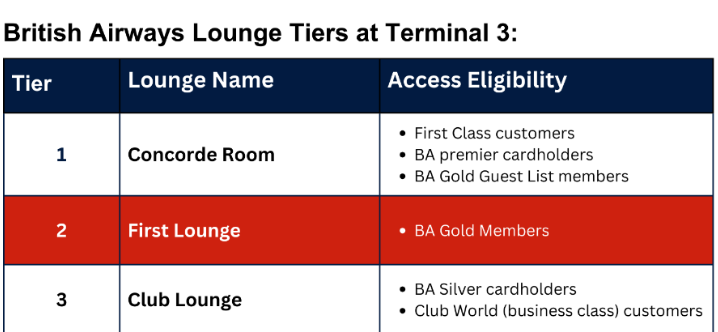

In [124]:
%pip install openpyxl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [125]:
data = pd.read_excel('flight_schedule.xlsx')
data.head(2)

,FLIGHT_DATE,FLIGHT_TIME,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28


In [126]:
# Finding Unique values in Haul, Time_of_Day, route_type to decide which column should be used for categorization
data["HAUL"].unique()

array(['LONG', 'SHORT'], dtype=object)

In [127]:
data["TIME_OF_DAY"].unique()

array(['Afternoon', 'Morning', 'Evening', 'Lunchtime'], dtype=object)

In [128]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   FLIGHT_DATE           10000 non-null  datetime64[ns]
 1   FLIGHT_TIME           10000 non-null  object        
 2   TIME_OF_DAY           10000 non-null  object        
 3   AIRLINE_CD            10000 non-null  object        
 4   FLIGHT_NO             10000 non-null  object        
 5   DEPARTURE_STATION_CD  10000 non-null  object        
 6   ARRIVAL_STATION_CD    10000 non-null  object        
 7   ARRIVAL_COUNTRY       10000 non-null  object        
 8   ARRIVAL_REGION        10000 non-null  object        
 9   HAUL                  10000 non-null  object        
 10  AIRCRAFT_TYPE         10000 non-null  object        
 11  FIRST_CLASS_SEATS     10000 non-null  int64         
 12  BUSINESS_CLASS_SEATS  10000 non-null  int64         
 13  ECONOMY_SEATS    

In [129]:
data.head()

,FLIGHT_DATE,FLIGHT_TIME,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27


In [130]:
data[["HAUL", 'TIME_OF_DAY', "ARRIVAL_REGION"]].shape

(10000, 3)

In [131]:
data["HAUL"].unique()

array(['LONG', 'SHORT'], dtype=object)

In [132]:
data["TIME_OF_DAY"].unique()

array(['Afternoon', 'Morning', 'Evening', 'Lunchtime'], dtype=object)

In [133]:
data["ARRIVAL_REGION"].unique()

array(['North America', 'Europe', 'Asia', 'Middle East'], dtype=object)

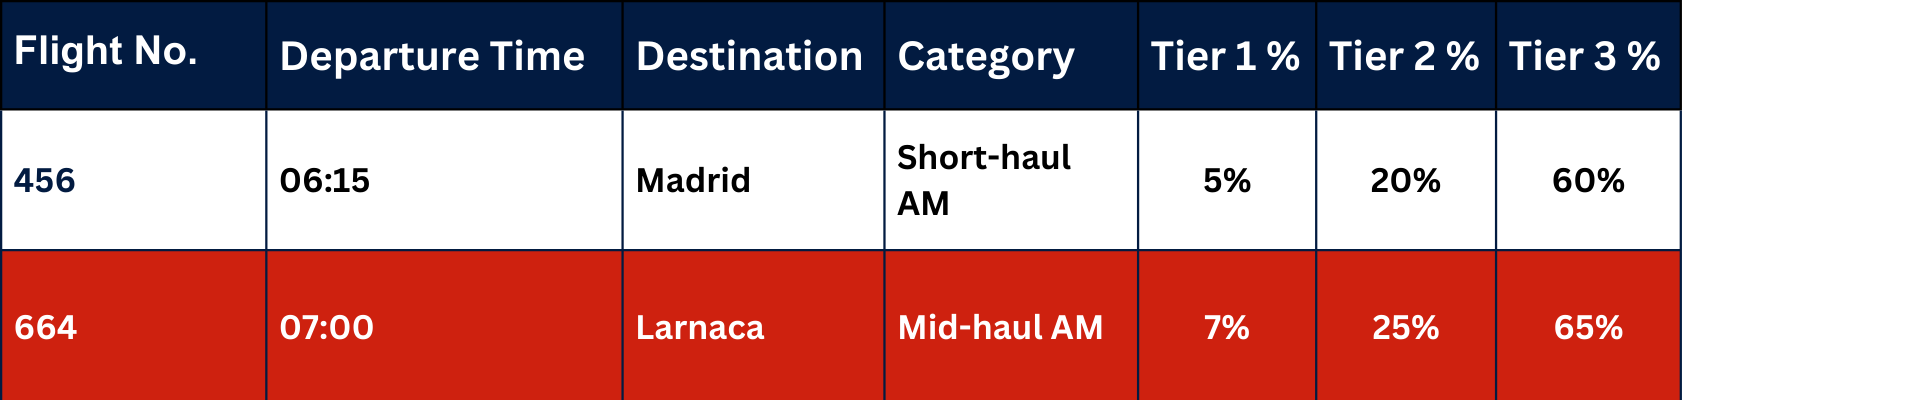

In [134]:
data.head()

,FLIGHT_DATE,FLIGHT_TIME,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27


In [135]:
flights = data.copy()

In [136]:
flights["Flight No."] = flights["FLIGHT_NO"].str.replace("BA", " ", regex = False)

In [137]:
# We have decided to group the flights on the basis of timing, (Morning Flights specifically)
flights.rename(columns = {"FLIGHT_TIME": "Departure Time"}, inplace= True)

In [145]:
flights

,FLIGHT_DATE,Departure Time,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX,Flight No.
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38,5211
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28,7282
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40,1896
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54,5497
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27,1493
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2025-06-07,22:04:00,Evening,BA,BA7039,LHR,VIE,Austria,Europe,SHORT,A320,0,7,173,1,15,51,7039
9996,2025-04-22,15:15:00,Afternoon,BA,BA9712,LHR,ORD,USA,North America,LONG,B777,8,49,178,1,0,0,9712
9997,2025-08-16,06:11:00,Morning,BA,BA7513,LHR,HND,Japan,Asia,LONG,B777,0,32,304,0,4,19,7513
9998,2025-10-24,22:02:00,Evening,BA,BA9958,LHR,DXB,UAE,Middle East,LONG,B787,8,48,200,1,10,38,9958


In [151]:
flights["total_seats"]= flights["FIRST_CLASS_SEATS"] + flights["BUSINESS_CLASS_SEATS"] + flights["ECONOMY_SEATS"]

In [156]:
flights["Tier 1%"] = ((flights["TIER1_ELIGIBLE_PAX"]/flights["total_seats"])*100).round()

In [157]:
flights["Tier 2%"] = ((flights["TIER2_ELIGIBLE_PAX"]/flights["total_seats"])*100).round()

In [158]:
flights["Tier 3%"] = ((flights["TIER3_ELIGIBLE_PAX"]/flights["total_seats"])*100).round()

In [160]:
flights.rename(columns = {'ARRIVAL_COUNTRY': "Destination"}, inplace = True)

In [162]:
flights.rename(columns = {'HAUL': "Category"}, inplace = True)

In [163]:
flights

,FLIGHT_DATE,Departure Time,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,Destination,ARRIVAL_REGION,Category,...,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX,Flight No.,Tier 1%,Tier 2%,Tier 3%,total_seats
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,...,49,178,0,10,38,5211,0.0,4.0,16.0,235
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,...,49,178,0,7,28,7282,0.0,3.0,12.0,235
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,...,17,163,0,11,40,1896,0.0,6.0,22.0,180
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,...,8,172,0,16,54,5497,0.0,9.0,30.0,180
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,...,13,167,0,6,27,1493,0.0,3.0,15.0,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2025-06-07,22:04:00,Evening,BA,BA7039,LHR,VIE,Austria,Europe,SHORT,...,7,173,1,15,51,7039,1.0,8.0,28.0,180
9996,2025-04-22,15:15:00,Afternoon,BA,BA9712,LHR,ORD,USA,North America,LONG,...,49,178,1,0,0,9712,0.0,0.0,0.0,235
9997,2025-08-16,06:11:00,Morning,BA,BA7513,LHR,HND,Japan,Asia,LONG,...,32,304,0,4,19,7513,0.0,1.0,6.0,336
9998,2025-10-24,22:02:00,Evening,BA,BA9958,LHR,DXB,UAE,Middle East,LONG,...,48,200,1,10,38,9958,0.0,4.0,15.0,256


In [175]:
flights["Grouping"] = (flights["TIME_OF_DAY"] + " " + flights["Category"])

In [176]:
flights.head()

,FLIGHT_DATE,Departure Time,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,Destination,ARRIVAL_REGION,Category,...,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX,Flight No.,Tier 1%,Tier 2%,Tier 3%,total_seats,Grouping
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,...,178,0,10,38,5211,0.0,4.0,16.0,235,Afternoon LONG
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,...,178,0,7,28,7282,0.0,3.0,12.0,235,Morning LONG
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,...,163,0,11,40,1896,0.0,6.0,22.0,180,Afternoon SHORT
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,...,172,0,16,54,5497,0.0,9.0,30.0,180,Evening SHORT
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,...,167,0,6,27,1493,0.0,3.0,15.0,180,Evening SHORT


In [181]:
flight_assumption = flights[["Grouping", "Destination", "Tier 1%", "Tier 2%", "Tier 3%"]].copy()

In [186]:
flight_assumption["Tier 1%"].unique()


array([ 0.,  1.,  2.,  3.,  5., 11.,  4.])